<a href="https://colab.research.google.com/github/mirzakamran123-max/smlds_assignment/blob/main/smlds_assignment.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

sns.set_theme(style="whitegrid")
df = pd.read_csv("housing.csv")


# Rizvi College of Engineering
**Department of Artificial Intelligence & Data Science Engineering**

**Course:** Statistics for Machine Learning and Data Science (2015111)

**Assignment No:** 01

**Class:** T.E (AI&DS)

**Semester:** V

**Student Name:** Mirza Kamran Furquan Baig

**UIN:** 231A036

**Date of Submission:** 08/07/2026

**Topic:** Exploratory Data Analysis (EDA) on the California Housing Dataset

# Part A: Dataset Understanding

## 1. Description
The California Housing dataset is derived from the **1990 US Census**. Each row represents one **census block group**, the smallest geographical unit for which the Census Bureau publishes data (typically 600 to 3,000 people). Each record describes the location, housing stock, population, and income of that block group. The goal is to understand which factors influence the **median house value** of an area.

## 2. Dataset Details
| Item | Details |
|---|---|
| Source | Kaggle: California Housing Prices (https://www.kaggle.com/datasets/camnugent/california-housing-prices) |
| Number of samples | ____ (from `df.shape`) |
| Number of features | ____ predictors + 1 target (from `df.shape`) |
| Target variable | `median_house_value` |
| Type of problem | Supervised learning: **Regression** |

## 3. Feature Dictionary
| Column | Meaning | Type |
|---|---|---|
| longitude / latitude | Geographic location of the block group | Numeric |
| housing_median_age | Median age of houses in the block | Numeric |
| total_rooms | Total rooms in the block | Numeric |
| total_bedrooms | Total bedrooms in the block | Numeric |
| population | Number of residents in the block | Numeric |
| households | Number of households in the block | Numeric |
| median_income | Median household income (in tens of thousands of USD) | Numeric |
| median_house_value | Median house value in USD (**target**) | Numeric |
| ocean_proximity | Distance category from the ocean | Categorical |

# Part B: Data Inspection

**Theory:** Data inspection is the first step of EDA. Before any analysis we need to know the size of the data, the data type of each column, whether values are missing, and whether rows are duplicated. Wrong data types, missing values, and duplicates can silently distort statistics and model results. Pandas functions used: `head()`/`tail()` (preview), `info()` (types and non-null counts), `isnull().sum()` (missing values), `duplicated().sum()` (duplicates), `describe()` (summary statistics).

In [2]:
display(df.head())
display(df.tail())
df.info()
print(df.dtypes)
print(df.isnull().sum())
print("Duplicates:", df.duplicated().sum())
display(df.describe(include="all"))

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
20635,-121.09,39.48,25.0,1665.0,374.0,845.0,330.0,1.5603,78100.0,INLAND
20636,-121.21,39.49,18.0,697.0,150.0,356.0,114.0,2.5568,77100.0,INLAND
20637,-121.22,39.43,17.0,2254.0,485.0,1007.0,433.0,1.7000,92300.0,INLAND
20638,-121.32,39.43,18.0,1860.0,409.0,741.0,349.0,1.8672,84700.0,INLAND
20639,-121.24,39.37,16.0,2785.0,616.0,1387.0,530.0,2.3886,89400.0,INLAND


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  float64
 3   total_rooms         20640 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20640 non-null  float64
 6   households          20640 non-null  float64
 7   median_income       20640 non-null  float64
 8   median_house_value  20640 non-null  float64
 9   ocean_proximity     20640 non-null  object 
dtypes: float64(9), object(1)
memory usage: 1.6+ MB
longitude             float64
latitude              float64
housing_median_age    float64
total_rooms           float64
total_bedrooms        float64
population            float64
households            float64
median_income         float64
median_hous

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
count,20640.000000,20640.000000,20640.000000,20640.000000,20433.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640
unique,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,5
top,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,<1H OCEAN
freq,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,9136
mean,-119.569704,35.631861,28.639486,2635.763081,537.870553,1425.476744,499.539680,3.870671,206855.816909,NaN
std,2.003532,2.135952,12.585558,2181.615252,421.385070,1132.462122,382.329753,1.899822,115395.615874,NaN
min,-124.350000,32.540000,1.000000,2.000000,1.000000,3.000000,1.000000,0.499900,14999.000000,NaN
25%,-121.800000,33.930000,18.000000,1447.750000,296.000000,787.000000,280.000000,2.563400,119600.000000,NaN
50%,-118.490000,34.260000,29.000000,2127.000000,435.000000,1166.000000,409.000000,3.534800,179700.000000,NaN
75%,-118.010000,37.710000,37.000000,3148.000000,647.000000,1725.000000,605.000000,4.743250,264725.000000,NaN


### Observations
- The dataset has **20,640 rows and 10 columns**. **9 columns are numeric** (float64) and **1 is categorical** (`ocean_proximity`, dtype object, with 5 unique categories).
- Missing values: only `total_bedrooms` has missing entries (**207 values, about 1.0% of rows**). All other columns are complete (20,640 non-null).
- Duplicate records: **0**.
- From `describe()`: the maximum of `median_house_value` is **500,001** and the maximum of `housing_median_age` is **52**. Both look like artificial ceilings rather than natural values, since 500,001 is an odd, round-looking cap and the age maximum sits only 23 years above the median of 29. Many rows sit at exactly these maximums, which suggests the values were **capped** by the data collectors (confirmed with `value_counts()`: ____ rows have a house value of 500,001 and ____ rows have an age of 52).
- `total_rooms` (max 39,320 vs 75th percentile 3,148), `total_bedrooms` (max 6,445 vs 647), and `population` (max 35,682 vs 1,725) have a maximum **more than 10 times larger than the 75th percentile**, which indicates extreme outliers.
- `ocean_proximity` is dominated by the category `<1H OCEAN` (9,136 rows, about 44% of the data).

# Part C: Data Visualisation

**Theory:** Visualisation reveals patterns that summary numbers hide.
- **Histogram:** shows the distribution (shape, centre, spread, skew) of one numeric variable.
- **Box plot:** shows the median, quartiles, and outliers (points beyond 1.5 × IQR from the box). Useful for comparing groups.
- **Scatter plot:** shows the relationship between two numeric variables (direction, strength, linear or not).
- **Pair plot:** a grid of scatter plots and histograms for several variables at once, to spot relationships quickly.
- **Correlation heatmap:** shows Pearson's correlation coefficient *r* (from -1 to +1) between every pair of numeric variables. Values near ±1 indicate a strong linear relationship; near 0 indicates little or none.
- *Correlation does not imply causation.*

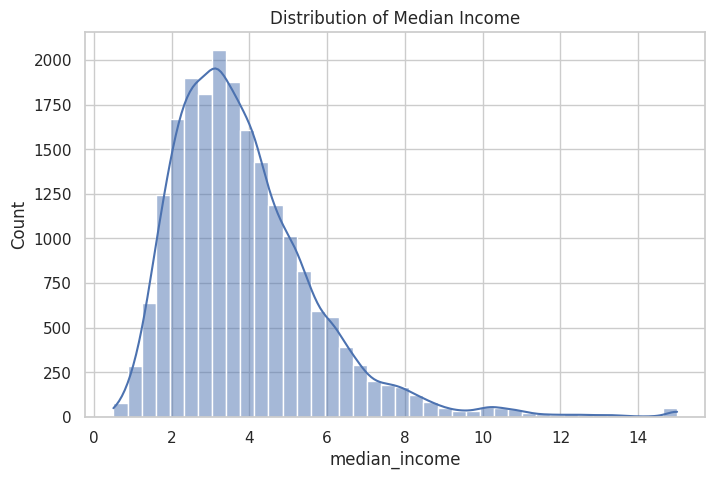

In [4]:
# 1. Histogram
plt.figure(figsize=(8,5))
sns.histplot(df["median_income"], bins=40, kde=True)
plt.title("Distribution of Median Income"); plt.show()



### Observations (Histogram of median_income)
- The distribution is **right-skewed** (skewness = 1.65) with most block groups earning between **about 2 and 5** (consistent with the 25th to 75th percentile of 2.56 to 4.74). The mean (3.87) is above the median (3.53), which fits a right skew.
- The peak (mode) is around **3 (roughly 3.0 to 3.5)**, where the tallest bar reaches a count of about 2,000.
- The right tail is long: few block groups have very high incomes above **8**, and the counts drop to almost zero beyond about 10. There is also a small isolated spike at **15**, the maximum value, which suggests the highest incomes were capped at 15 (about $150,000). These extreme values will matter for outlier treatment in Part E.

fill in the blank space

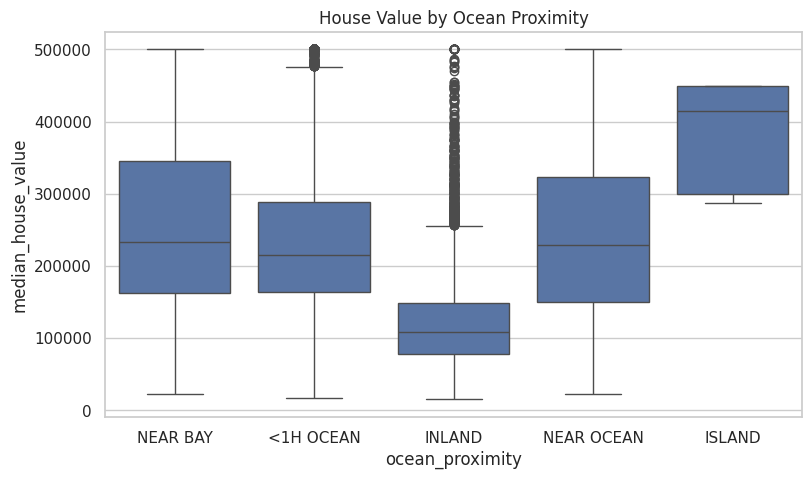

In [6]:
# 2. Box plot
plt.figure(figsize=(9,5))
sns.boxplot(x="ocean_proximity", y="median_house_value", data=df)
plt.title("House Value by Ocean Proximity"); plt.show()


### Observations (Box plot: house value by ocean_proximity)
- The category with the highest median house value is **ISLAND** (about 415,000), and the lowest is **INLAND** (about 108,000). The other three categories have similar medians: NEAR BAY (about 233,000), NEAR OCEAN (about 229,000), and <1H OCEAN (about 215,000). So the main split is between inland areas and areas near the coast.
- **INLAND** shows many outliers at the top, forming a dense line of points from about 255,000 up to 500,000. A smaller cluster of outliers also sits at **500,000** for **<1H OCEAN** (from about 475,000 upward). These values at 500,000 are the capped value of `median_house_value`. NEAR BAY, NEAR OCEAN, and INLAND also reach the 500,000 line.
- The category **NEAR BAY** has the widest spread (IQR about 163,000 to 346,000, roughly 183,000), meaning prices there are the most variable. NEAR OCEAN is a close second (about 150,000 to 324,000). INLAND has the narrowest box (about 78,000 to 149,000), so its typical prices are tightly clustered even though it has many high-value outliers.
- The ISLAND box looks compact and has no whiskers or outliers, but this category has very few rows, so its median should be treated with caution.

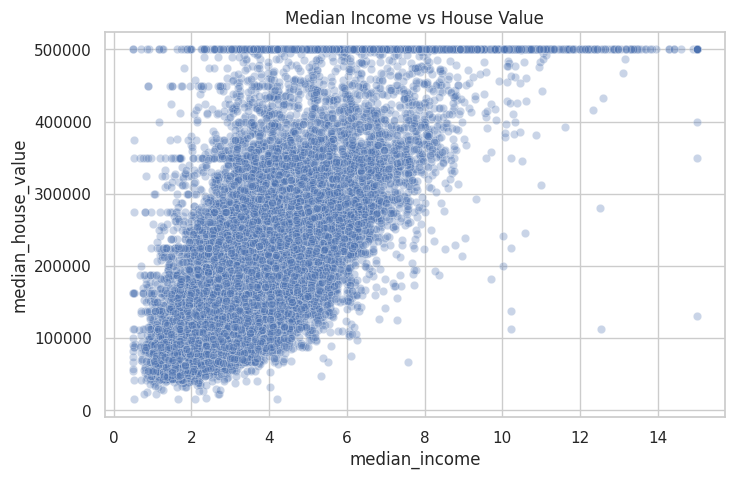

In [7]:
# 3. Scatter plot
plt.figure(figsize=(8,5))
sns.scatterplot(x="median_income", y="median_house_value", data=df, alpha=0.3)
plt.title("Median Income vs House Value"); plt.show()

### Observations (median_income vs median_house_value)
- There is a **positive**, **moderate-to-strong** relationship (r = **____**, see the check below): as income rises, house value **tends to rise as well**. The cloud slopes upward, with most points between incomes of 2 to 6 and house values of 50,000 to 350,000.
- A horizontal line of points appears at **500,000**, caused by the capping of house values; this can mislead a regression model, because it treats all block groups above this value as exactly 500,000 even though their true values are higher. Fainter horizontal lines are also visible near **350,000** and **450,000**, which suggests that some values were rounded or capped at other levels too.
- The spread of house values **increases** as income grows (the points fan out like a funnel, narrow at low income and wide at high income), which suggests **heteroscedasticity** (non-constant variance). A simple linear regression would therefore be less reliable at high incomes. At incomes above about 8 the points become sparse and scattered, with a few block groups that have very high income but low house value (e.g. around 15 on the x-axis, where house values range from about 130,000 to 500,000).

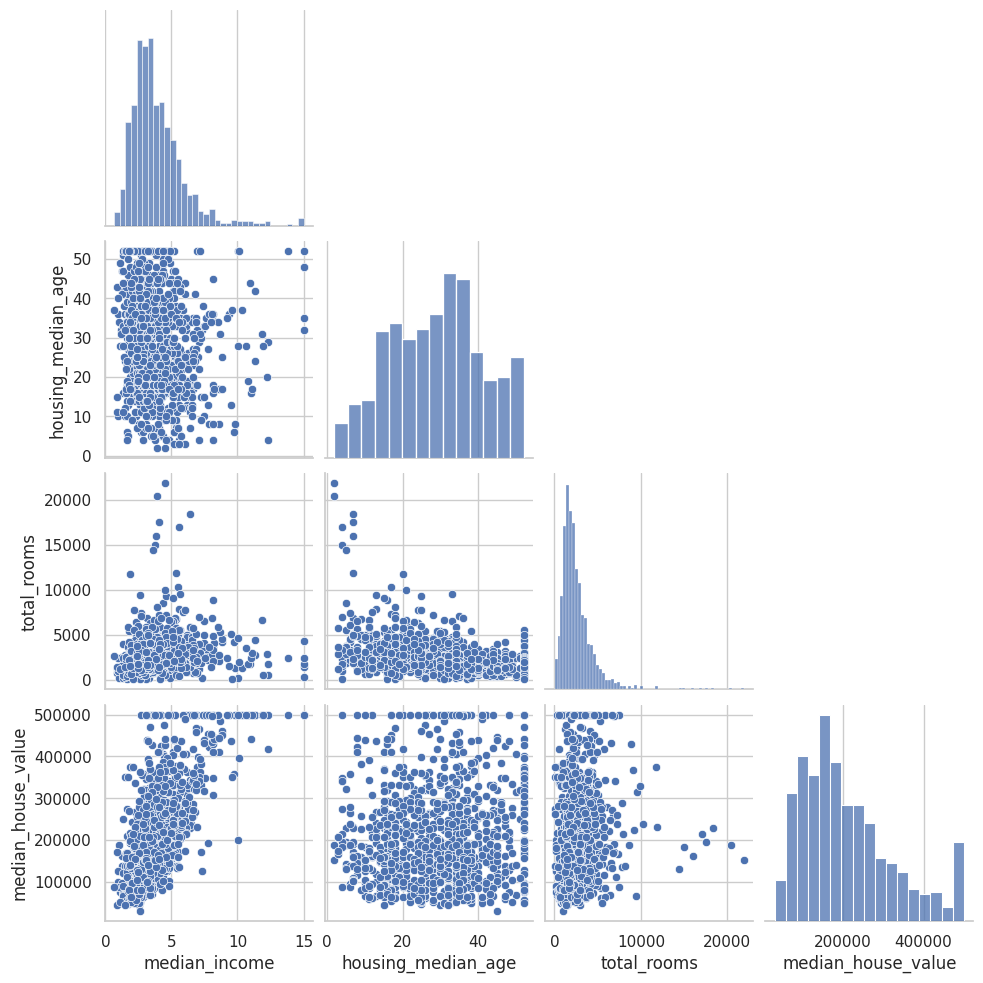

In [8]:
# 4. Pair plot (sampled so it runs fast)
cols = ["median_income", "housing_median_age", "total_rooms", "median_house_value"]
sns.pairplot(df[cols].sample(1000, random_state=42), corner=True)
plt.show()

### Observations (Pair plot)
- `median_income` and `median_house_value` show the clearest **positive, roughly linear** pattern: the points rise from the bottom left to the top right, and they pile up along a horizontal line at 500,000 (the capped value).
- `total_rooms` shows a **weak or no clear** relationship with **`median_income`, `housing_median_age`, and `median_house_value`** (the points form a shapeless cloud), and is heavily **right**-skewed with many values bunched near the low end (most below about 5,000, with a few extreme block groups above 15,000). There is a slight downward trend against `housing_median_age`: the largest `total_rooms` values occur in younger housing, while older block groups (age around 50) all have smaller totals.
- The diagonal histograms show **right** skewness in **`median_income`, `total_rooms`, and `median_house_value`**, which may need transformation or outlier handling. `total_rooms` is the most extreme. `median_house_value` is also right-skewed but has an unusual spike at the highest bin (500,000) because of capping. `housing_median_age` is the exception: it is roughly symmetric with a slight lean toward older ages, and a pile-up at 52 (the maximum), so it needs capping awareness rather than skew correction.

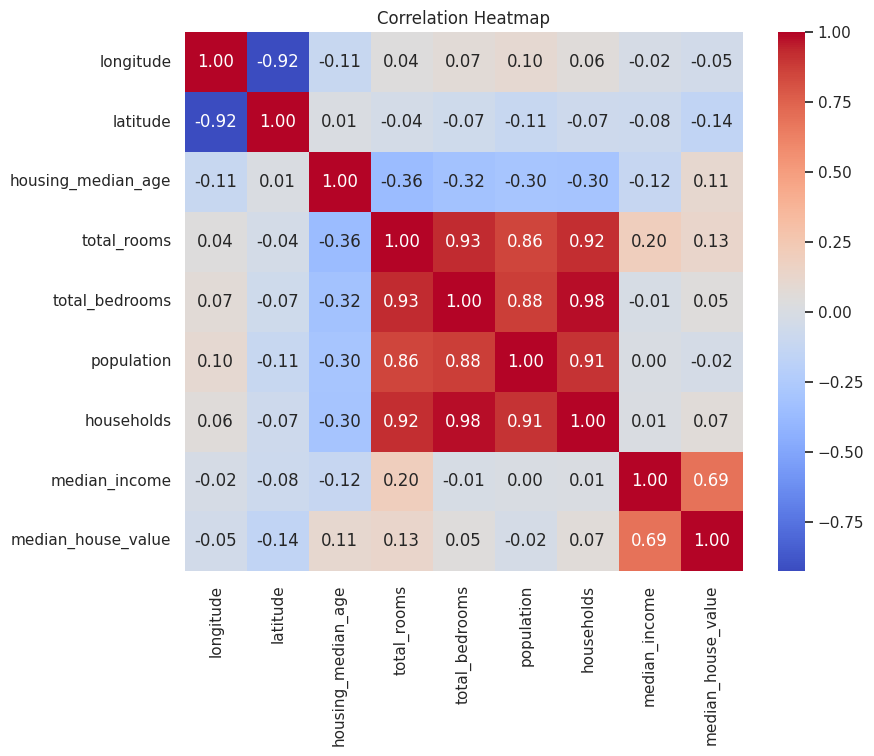

In [9]:
# 5. Correlation heatmap
plt.figure(figsize=(9,7))
sns.heatmap(df.select_dtypes("number").corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Correlation Heatmap"); plt.show()

### Observations (Correlation heatmap)
- Strongest correlation with the target: `median_income` (r = **0.69**). This makes it the most useful single predictor. The next strongest are weak: `latitude` (r = -0.14) and `total_rooms` (r = 0.13).
- Strongly correlated predictor pairs: `total_rooms`–`total_bedrooms`–`households`–`population` (r ≈ **0.86 to 0.98**). The highest is `total_bedrooms`–`households` (0.98), and the lowest is `total_rooms`–`population` (0.86). This is **multicollinearity**, and it can make linear-model coefficients unstable.
- Weakest correlation with the target: `population` (r = **-0.02**), which is essentially zero. `total_bedrooms` (0.05) and `longitude` (-0.05) are also very weak.
- Latitude and longitude are strongly (negatively) correlated with each other (r = **-0.92**) because California's coastline runs diagonally from the north-west to the south-east.

# Part D: Descriptive Statistics

**Theory:**
| Measure | Formula / idea | What it tells us |
|---|---|---|
| Mean | Σx / n | Average value; sensitive to outliers |
| Median | Middle value of sorted data | Typical value; robust to outliers |
| Mode | Most frequent value | Most common value |
| Variance | Σ(x − mean)² / (n − 1) | Average squared spread around the mean |
| Std deviation | √Variance | Spread in the original units |
| Range | max − min | Total spread; very sensitive to outliers |
| IQR | Q3 − Q1 | Spread of the middle 50%; robust to outliers |
| Skewness | Third standardised moment | 0 = symmetric; > 0 = right (long right tail); < 0 = left |
| Kurtosis (excess) | Fourth standardised moment − 3 | 0 = normal-like tails; > 0 = heavy tails / more outliers; < 0 = light tails |

**Rule of thumb:** if mean > median, the data is usually right-skewed.

In [10]:
num_cols = ["median_income", "housing_median_age", "total_rooms", "population", "median_house_value"]
rows = []
for c in num_cols:
    s = df[c].dropna()
    rows.append({
        "Feature": c, "Mean": s.mean(), "Median": s.median(), "Mode": s.mode()[0],
        "Variance": s.var(), "Std Dev": s.std(), "Range": s.max()-s.min(),
        "IQR": s.quantile(.75)-s.quantile(.25),
        "Skewness": s.skew(), "Kurtosis": s.kurt()
    })
stats_df = pd.DataFrame(rows).round(2)
display(stats_df)

,Feature,Mean,Median,Mode,Variance,Std Dev,Range,IQR,Skewness,Kurtosis
0,median_income,3.87,3.53,3.12,3.610000e+00,1.90,14.5,2.18,1.65,4.95
1,housing_median_age,28.64,29.00,52.00,1.584000e+02,12.59,51.0,19.00,0.06,-0.80
2,total_rooms,2635.76,2127.00,1527.00,4.759445e+06,2181.62,39318.0,1700.25,4.15,32.63
3,population,1425.48,1166.00,891.00,1.282470e+06,1132.46,35679.0,938.00,4.94,73.55
4,median_house_value,206855.82,179700.00,500001.00,1.331615e+10,115395.62,485002.0,145125.00,0.98,0.33


### Interpretation
- **median_income:** mean (**3.87**) vs median (**3.53**), so the distribution is **right-skewed** (the mean is pulled up by a few high incomes). Skewness = **1.65** and kurtosis = **4.95**, indicating **a strong positive skew and heavy tails (more extreme values than a normal distribution)**.
- **total_rooms:** mean (**2,635.76**) is much **higher** than the median (**2,127**), the range is **39,318**, and skewness = **4.15** (kurtosis = **32.63**), so the feature has a very long right tail and many outliers. `population` behaves the same way (skewness 4.94, kurtosis 73.55, range 35,679) and is the most extreme feature in the table.
- **housing_median_age:** skewness is **0.06**, so it is roughly **symmetric**. Its kurtosis is **-0.80**, which means the distribution is flatter than a normal curve with light tails, and its mode (**52**) equals the maximum, which again points to capping.
- **median_house_value:** skewness = **0.98** (moderately right-skewed), with a pile-up at the maximum (**500,001**, which is also the mode) because of capping. Its kurtosis (0.33) is close to normal, so the capped values, rather than a long tail, are the main issue.
- Features with a large IQR relative to the range have **values spread more evenly with few extreme values** (e.g. `housing_median_age`: IQR 19 out of a range of 51, about 37%), while features where range ≫ IQR contain extreme values (e.g. `total_rooms`: IQR 1,700 vs range 39,318, about 4%; `population`: IQR 938 vs range 35,679, about 3%).

# Part E: Data Preprocessing

**Theory:** Raw data is rarely ready for machine learning. Preprocessing improves data quality so models learn real patterns rather than noise or artefacts. The four steps below handle missing values, outliers, categorical text, and differing feature scales.

### Step 1: Handling Missing Values
**Action:** Filled missing `total_bedrooms` values with the **median**.
**Justification:** Only about 1% of rows are affected, so deleting them would lose little data, but imputing keeps all rows. The median is used instead of the mean because `total_bedrooms` is heavily right-skewed, and the median is not pulled up by extreme values. Median imputation preserves the overall distribution. A limitation is that it reduces variance slightly and ignores relationships with other columns.

In [11]:
clean = df.copy()
# 1. Missing values
clean["total_bedrooms"] = clean["total_bedrooms"].fillna(clean["total_bedrooms"].median())

### Step 2: Treating Outliers
**Action:** Capped (winsorised) `total_rooms`, `total_bedrooms`, `population`, and `households` at Q1 − 1.5×IQR and Q3 + 1.5×IQR.
**Justification:** These features have extreme right tails (see box plots, skewness, kurtosis). Extreme values pull the mean, inflate variance, and can dominate distance-based or linear models. Capping keeps every row, which matters because the extreme values may be real (large urban block groups) rather than errors. Removing them would delete genuine areas and shrink the dataset. `median_house_value` was not capped because it is the target, and its ceiling at 500,001 is a data-collection limit rather than a statistical outlier. This is noted as a limitation.

In [12]:
# 2. Outliers: IQR capping on skewed count features
for c in ["total_rooms", "total_bedrooms", "population", "households"]:
    q1, q3 = clean[c].quantile(.25), clean[c].quantile(.75)
    iqr = q3 - q1
    clean[c] = clean[c].clip(q1 - 1.5*iqr, q3 + 1.5*iqr)

### Step 3: Encoding the Categorical Variable
**Action:** One-hot encoded `ocean_proximity` with `drop_first=True`.
**Justification:** Machine learning models need numeric input. The categories have **no natural order** (nominal), so label encoding (0, 1, 2…) would wrongly imply that one category is "greater" than another. One-hot encoding creates independent binary columns, and `drop_first=True` removes one redundant column to avoid the dummy-variable trap (perfect multicollinearity).

In [13]:
# 3. Encode categorical variable
clean = pd.get_dummies(clean, columns=["ocean_proximity"], drop_first=True, dtype=int)


### Step 4: Standardisation
**Action:** Applied `StandardScaler` (z = (x − mean) / std) to the numeric predictors.
**Justification:** Features have very different scales (e.g. `population` in thousands vs `median_income` in single digits). Scale-sensitive algorithms (linear/logistic regression with regularisation, k-NN, SVM, gradient descent, PCA) would be dominated by large-scale features. Standardisation gives each feature mean 0 and standard deviation 1. It was chosen over Min-Max scaling because it is less distorted by the remaining outliers. The target was left unscaled so predictions stay in dollars.

In [14]:
# 4. Standardise numeric features (not the target)
to_scale = ["longitude","latitude","housing_median_age","total_rooms",
            "total_bedrooms","population","households","median_income"]
clean[to_scale] = StandardScaler().fit_transform(clean[to_scale])

In [15]:
print("Missing values left:", clean.isnull().sum().sum())
display(clean.head())

Missing values left: 0


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity_INLAND,ocean_proximity_ISLAND,ocean_proximity_NEAR BAY,ocean_proximity_NEAR OCEAN
0,-1.327835,1.052548,0.982143,-1.117285,-1.309916,-1.325821,-1.291972,2.344766,452600.0,0,0,1,0
1,-1.322844,1.043185,-0.607019,2.329936,2.128690,1.389936,2.348314,2.332238,358500.0,0,0,1,0
2,-1.332827,1.038503,1.856182,-0.697327,-1.095223,-1.098528,-1.099883,1.782699,352100.0,0,0,1,0
3,-1.337818,1.038503,1.856182,-0.835405,-0.936843,-1.017539,-0.941691,0.932968,341300.0,0,0,1,0
4,-1.337818,1.038503,1.856182,-0.582857,-0.778463,-1.008395,-0.791033,-0.012881,342200.0,0,0,1,0


### Responsible Data Handling (CO6)
- **Location as a proxy:** `latitude`, `longitude`, and `ocean_proximity` can act as proxies for neighbourhood demographics. A model trained on them may reproduce historical patterns of housing inequality (e.g. redlining effects) even without using race or income group directly.
- **Aggregated data:** Each row is a block group, not a house or person, so conclusions apply to areas and should not be applied to individual households (ecological fallacy).
- **Old data:** The data is from 1990, so predictions would not reflect today's market.
- **Imputation and capping** change the data, so they should be documented and their effect on results checked.

# Part F: Sampling

**Theory:**
- **Population vs sample:** A sample is a subset used to draw conclusions about the full population.
- **Simple Random Sampling (SRS):** every record has an equal chance of selection. It is unbiased and easy, but a small sample may by chance under-represent small groups.
- **Stratified Sampling:** the population is divided into groups (strata) and a sample is drawn from each in proportion to its size. It guarantees representation of every group and usually gives lower variance than SRS.
- Here, `ocean_proximity` is the stratification variable because it is categorical and the groups are unequal in size (`ISLAND` is very rare).

In [16]:
n = 1000
srs = df.sample(n=n, random_state=42)
strat, _ = train_test_split(df, train_size=n, stratify=df["ocean_proximity"], random_state=42)

comparison = pd.DataFrame({
    "Full": [df["median_income"].mean(), df["median_house_value"].mean(), df["median_house_value"].std()],
    "Simple Random": [srs["median_income"].mean(), srs["median_house_value"].mean(), srs["median_house_value"].std()],
    "Stratified": [strat["median_income"].mean(), strat["median_house_value"].mean(), strat["median_house_value"].std()],
}, index=["Income mean", "House value mean", "House value std"])
display(comparison.round(2))

props = pd.DataFrame({
    "Full": df["ocean_proximity"].value_counts(normalize=True),
    "SRS": srs["ocean_proximity"].value_counts(normalize=True),
    "Stratified": strat["ocean_proximity"].value_counts(normalize=True),
}).round(4)
display(props)

,Full,Simple Random,Stratified
Income mean,3.87,3.94,3.78
House value mean,206855.82,209696.55,203786.93
House value std,115395.62,116431.31,112417.88


,Full,SRS,Stratified
ocean_proximity,,,
<1H OCEAN,0.4426,0.450,0.443
INLAND,0.3174,0.303,0.317
ISLAND,0.0002,NaN,NaN
NEAR BAY,0.1109,0.102,0.111
NEAR OCEAN,0.1288,0.145,0.129


### Interpretation
- Mean `median_income`: full = **3.87**, SRS = **3.94**, stratified = **3.78**. The **simple random** sample is closer to the population (a difference of 0.07, against 0.09 for the stratified sample), though both are close.
- Mean `median_house_value`: full = **206,855.82**, SRS = **209,696.55**, stratified = **203,786.93**. Again the SRS is slightly closer (about 2,841 away, against 3,069 for the stratified sample). The standard deviations are also similar: full = 115,395.62, SRS = 116,431.31, stratified = 112,417.88.
- Category proportions: the stratified sample matches the population proportions almost exactly (e.g. INLAND ≈ **31.7%** vs 31.74% in the population), while the SRS differs by up to **1.6** percentage points (NEAR OCEAN: 14.5% in the SRS vs 12.88% in the population; INLAND is off by about 1.4 points). The rare `ISLAND` category (population **0.02%**, only a handful of rows) does not appear in **either** sample (NaN in both), because with n = 1000 the expected number of ISLAND rows is well under one.
- **Conclusion:** both samples approximate the population well because n = 1000 is reasonably large. Stratified sampling reproduces the category proportions more closely, but it does not guarantee closer means for numeric variables such as income and house value, since it only controls `ocean_proximity`. Neither method captured the very rare ISLAND category, which is a limitation of using a small sample for a tiny group. Stratified sampling is still the better choice when groups are unbalanced, and a larger sample or a minimum quota per stratum would be needed to include ISLAND.

# Part G: Conclusion

**Major insights:** `median_income` is the strongest predictor of house value (r = **0.69**). Location also matters: **coastal and bay-area (NEAR BAY, NEAR OCEAN, <1H OCEAN)** areas have the highest values among the well-populated categories (medians of roughly 215,000 to 233,000), while **INLAND** areas are much cheaper (median about 108,000). The ISLAND category has the highest median (about 415,000) but contains too few rows to generalise from. House values are **right**-skewed (skewness = 0.98).

**Data quality issues:** (1) **207** missing values in `total_bedrooms` (about 1% of rows); (2) `median_house_value` and `housing_median_age` are capped at **500,001** and **52**, and `median_income` appears capped at about 15; (3) heavy outliers in `total_rooms`, `population`, `households` (e.g. `total_rooms` skewness 4.15 and `population` skewness 4.94, with maximums many times the 75th percentile); (4) the very rare `ISLAND` category with only **5** rows, which was missing from both samples in Part F.

**Important relationships:** income and house value (positive, r = **0.69**); `total_rooms`, `total_bedrooms`, `households`, `population` are highly inter-correlated (r = 0.86 to 0.98, multicollinearity) and each is only weakly related to house value (|r| ≤ 0.13); latitude and longitude are strongly correlated with each other (r = -0.92).

**Suitability for ML:** The dataset is large (20,640 rows) and mostly clean, so it is well suited to regression models (e.g. Linear Regression, Random Forest) after the preprocessing above. Limitations: the capped target (500,001), multicollinearity, the funnel-shaped spread of values at high incomes (heteroscedasticity), and the fairness concerns noted in Part E, such as location acting as a proxy for neighbourhood demographics and the data dating from 1990.

# AI Ethical Usage Declaration
I declare that this assignment is my original work. Any Generative AI tools (such as ChatGPT, Gemini, GitHub Copilot, or similar) were used only to assist with learning, debugging, or improving code readability. I have independently verified all code, analysis, visualisations, interpretations, and conclusions presented in this notebook. Any external resources or AI assistance used have been appropriately acknowledged.